# Data Exploration and Quality Assessment

## Objectives

- Load the Appliances Energy Prediction dataset.
- Inspect the dataset structure and data types.
- Identify missing values and duplicate records.
- Check timestamp validity and temporal consistency.
- Define the target variable and explanatory features.
- Build a chronological training/evaluation split.

## Dataset Source

UCI Machine Learning Repository — Appliances Energy Prediction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("../data/raw/energydata_complete.csv")

TARGET = "Appliances"
DATE_COLUMN = "date"

print("Dataset exists:", DATA_PATH.exists())

Dataset exists: True


## 1. Load the Dataset

Load the CSV file and inspect its dimensions, columns, data types, and first records.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())
display(df.info())

Dataset shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

None

## 2. Initial Data Quality Assessment

Check missing values, duplicated rows, and column data types before applying any cleaning operation.

In [3]:
print("Total missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nColumn data types:")
display(df.dtypes)

Total missing values: 0
Duplicate rows: 0

Missing values per column:


date           0
T7             0
rv1            0
Tdewpoint      0
Visibility     0
Windspeed      0
RH_out         0
Press_mm_hg    0
T_out          0
RH_9           0
T9             0
RH_8           0
T8             0
RH_7           0
RH_6           0
Appliances     0
T6             0
RH_5           0
T5             0
RH_4           0
T4             0
RH_3           0
T3             0
RH_2           0
T2             0
RH_1           0
T1             0
lights         0
rv2            0
dtype: int64


Column data types:


date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object

## 3. Temporal Data Quality Assessment

Convert the date column to datetime format and investigate:

- Invalid timestamps.
- Duplicate timestamps.
- Chronological ordering.
- Time interval consistency.
- Missing time intervals.

In [4]:
df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="coerce"
)

invalid_dates = df[DATE_COLUMN].isna().sum()

print("Invalid timestamps:", invalid_dates)
print("Earliest timestamp:", df[DATE_COLUMN].min())
print("Latest timestamp:", df[DATE_COLUMN].max())

print(
    "Original chronological order:",
    df[DATE_COLUMN].is_monotonic_increasing
)

Invalid timestamps: 0
Earliest timestamp: 2016-01-11 17:00:00
Latest timestamp: 2016-05-27 18:00:00
Original chronological order: True


In [5]:
duplicate_dates = df[DATE_COLUMN].duplicated().sum()

print("Duplicate timestamps:", duplicate_dates)

if duplicate_dates > 0:
    display(
        df[df[DATE_COLUMN].duplicated(keep=False)]
        .sort_values(DATE_COLUMN)
        .head(10)
    )

Duplicate timestamps: 0


In [6]:
df_sorted = df.sort_values(DATE_COLUMN).reset_index(drop=True)

time_deltas = df_sorted[DATE_COLUMN].diff()

print("Most frequent time intervals:")
display(time_deltas.value_counts().head(10))

print("\nIntervals different from 10 minutes:")
display(time_deltas[time_deltas != pd.Timedelta(minutes=10)].value_counts())

print(
    "\nNumber of intervals different from 10 minutes:",
    (time_deltas.dropna() != pd.Timedelta(minutes=10)).sum()
)

Most frequent time intervals:


date
0 days 00:10:00    19734
Name: count, dtype: int64


Intervals different from 10 minutes:


Series([], Name: count, dtype: int64)


Number of intervals different from 10 minutes: 0


## 4. Target Variable and Feature Selection

The objective is to predict household appliance energy consumption.

- Target variable: `Appliances`
- Excluded from the initial feature set: `date`, `rv1`, and `rv2`
- Candidate explanatory variables: all remaining columns

The timestamp will be preserved separately for chronological splitting.
The two random variables will be excluded because they are not meaningful
predictors of appliance energy consumption.

In [7]:
TARGET = "Appliances"
EXCLUDED_FEATURES = ["date", "rv1", "rv2"]

# Check that all expected columns exist
assert TARGET in df.columns
assert all(col in df.columns for col in EXCLUDED_FEATURES)

feature_columns = [
    col for col in df.columns
    if col not in [TARGET] + EXCLUDED_FEATURES
]

X = df[feature_columns].copy()
y = df[TARGET].copy()
timestamps = df[DATE_COLUMN].copy()

print("Target:", TARGET)
print("Number of features:", len(feature_columns))
print("Features:", feature_columns)
print("Target shape:", y.shape)
print("Feature matrix shape:", X.shape)

Target: Appliances
Number of features: 25
Features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint']
Target shape: (19735,)
Feature matrix shape: (19735, 25)


## 5. Target Variable Analysis

Analyze the target distribution using descriptive statistics and
visualization to understand appliance energy consumption.

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

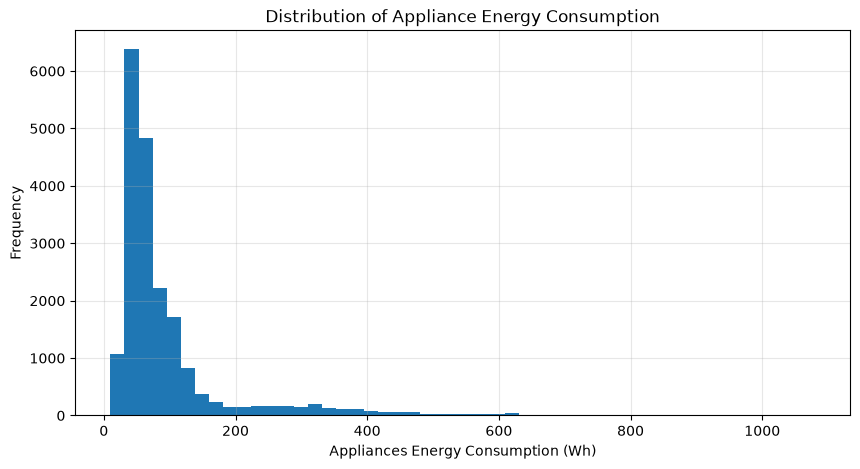

In [8]:
display(y.describe())

plt.figure(figsize=(10, 5))
plt.hist(y, bins=50)
plt.title("Distribution of Appliance Energy Consumption")
plt.xlabel("Appliances Energy Consumption (Wh)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

## 6. Chronological Dataset Versioning Strategy

We divide the dataset into three consecutive chronological periods:

- Dataset v1: the first 60% of observations, used for initial training.
- Historical extension: the following 20%, added to Dataset v2.
- Final test set: the last 20%, kept strictly isolated.

Dataset v1 and Dataset v2 will be evaluated on the exact same
final test observations.

The final test set must never be used for model fitting,
hyperparameter tuning, or model selection.

In [9]:
df_sorted = df.sort_values(DATE_COLUMN).reset_index(drop=True)

n = len(df_sorted)

idx_v1 = int(n * 0.60)
idx_v2 = int(n * 0.80)

train_v1 = df_sorted.iloc[:idx_v1].copy()

historical_extension = df_sorted.iloc[idx_v1:idx_v2].copy()

test_final = df_sorted.iloc[idx_v2:].copy()

train_v2 = df_sorted.iloc[:idx_v2].copy()

print("Dataset v1:", train_v1.shape)
print("Historical extension:", historical_extension.shape)
print("Dataset v2:", train_v2.shape)
print("Final test:", test_final.shape)

Dataset v1: (11841, 29)
Historical extension: (3947, 29)
Dataset v2: (15788, 29)
Final test: (3947, 29)


In [10]:
assert train_v1[DATE_COLUMN].max() < historical_extension[DATE_COLUMN].min()

assert historical_extension[DATE_COLUMN].max() < test_final[DATE_COLUMN].min()

assert train_v2[DATE_COLUMN].max() < test_final[DATE_COLUMN].min()

assert len(train_v1) + len(historical_extension) == len(train_v2)

print("Chronological separation: PASSED")
print("Final test isolation: PASSED")

Chronological separation: PASSED
Final test isolation: PASSED


In [11]:
periods = {
    "Dataset v1": train_v1,
    "Historical extension": historical_extension,
    "Dataset v2": train_v2,
    "Final test": test_final,
}

for name, dataset in periods.items():
    print(f"\n{name}")
    print("Observations:", len(dataset))
    print("Start:", dataset[DATE_COLUMN].min())
    print("End:", dataset[DATE_COLUMN].max())


Dataset v1
Observations: 11841
Start: 2016-01-11 17:00:00
End: 2016-04-02 22:20:00

Historical extension
Observations: 3947
Start: 2016-04-02 22:30:00
End: 2016-04-30 08:10:00

Dataset v2
Observations: 15788
Start: 2016-01-11 17:00:00
End: 2016-04-30 08:10:00

Final test
Observations: 3947
Start: 2016-04-30 08:20:00
End: 2016-05-27 18:00:00
